In [261]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import hstack
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, classification_report, confusion_matrix
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [262]:
df = pd.read_csv('song_recomendation_A.csv')
df.head()

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:38tpcZDofjtDNunMm5w1EU,If I Could Change Your Mind,HAIM,Days Are Gone (Deluxe Edition),2013-01-01,53,"indietronica,metropopolis",0.671,0.852,2.0,-5.557,0.0,0.0425,0.01840,0.000099,0.0841,0.737,125.043,4.0
1,spotify:track:60lJebAiPbIrnLeGev6kHX,If I Ain't Got You,Alicia Keys,The Diary Of Alicia Keys,2003,0,"neo soul,pop,r&b",0.589,0.449,7.0,-9.153,1.0,0.1050,0.60700,0.000022,0.1000,0.159,118.351,3.0
2,spotify:track:1dbt3sOwRmUOLfQZSpSz9O,Truly,Lionel Richie,Lionel Richie (Expanded Edition),1982,0,soft rock,0.366,0.238,1.0,-13.853,1.0,0.0381,0.64600,0.000010,0.0876,0.131,68.362,4.0
3,spotify:track:50PeqUz1BjMw9ayNTk5O4d,I've Been Thinking About You,Londonbeat,Best! The Singles 16 Tracks,1995-11-20,69,"eurodance,hip house",0.678,0.659,11.0,-12.695,0.0,0.0396,0.02360,0.001920,0.0744,0.899,113.542,4.0
4,spotify:track:111P8I22TrLyxQm7Jcwdoy,Kung Fu Fighting,"Bus Stop, Carl Douglas",The Soul of the Kung Fu Fighter,1972-02-13,0,NaN,0.737,0.855,11.0,-10.319,0.0,0.0646,0.00475,0.000017,0.1630,0.583,116.023,4.0


In [263]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           5000 non-null   object 
 1   Track Name          4999 non-null   object 
 2   Artist Name(s)      4999 non-null   object 
 3   Album Name          4999 non-null   object 
 4   Album Release Date  5000 non-null   object 
 5   Popularity          5000 non-null   int64  
 6   Artist Genres       4705 non-null   object 
 7   Danceability        5000 non-null   float64
 8   Energy              5000 non-null   float64
 9   Key                 5000 non-null   float64
 10  Loudness            5000 non-null   float64
 11  Mode                5000 non-null   float64
 12  Speechiness         5000 non-null   float64
 13  Acousticness        4850 non-null   float64
 14  Instrumentalness    5000 non-null   float64
 15  Liveness            5000 non-null   float64
 16  Valenc

In [264]:
print(f"Total Duplikat: {df.duplicated().sum()} baris")
print(f"Total Missing Values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")


Total Duplikat: 9 baris
Total Missing Values:
Track Name          1
Artist Name(s)      1
Album Name          1
Artist Genres     295
Acousticness      150
Tempo             250
dtype: int64


In [265]:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    
    for col in numeric_cols:
        stats = df[col].describe()
        
     
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
  
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        num_outliers = len(outliers)
        
        print(f"Kolom: {col.upper()}")
        print(f"   Range: {stats['min']} s/d {stats['max']}")
        print(f"   Jumlah Outlier (IQR): {num_outliers} baris")
        

        if col == 'Loudness' and stats['max'] > 0:
            print("  Ada anomali di loudness")
        if col == 'Popularity' and (df[col] == 0).sum() > 100:
            print(f"   ({ (df[col] == 0).sum() } lagu)")

    cat_cols = df.select_dtypes(include=['object']).columns
    
    for col in cat_cols:
        unique_count = df[col].nunique()
        print(f" Kolom: {col.upper()}")
        print(f"   Jumlah Nilai Unik: {unique_count}")
        print(f"   Top 3 Terbanyak: {df[col].value_counts().head(3).to_dict()}")



Kolom: POPULARITY
   Range: 0.0 s/d 95.0
   Jumlah Outlier (IQR): 0 baris
   (1344 lagu)
Kolom: DANCEABILITY
   Range: 0.0994 s/d 0.988
   Jumlah Outlier (IQR): 32 baris
Kolom: ENERGY
   Range: 0.0205 s/d 0.994
   Jumlah Outlier (IQR): 32 baris
Kolom: KEY
   Range: 0.0 s/d 11.0
   Jumlah Outlier (IQR): 0 baris
Kolom: LOUDNESS
   Range: -23.242 s/d 2.769
   Jumlah Outlier (IQR): 113 baris
  Ada anomali di loudness
Kolom: MODE
   Range: 0.0 s/d 1.0
   Jumlah Outlier (IQR): 0 baris
Kolom: SPEECHINESS
   Range: 0.0218 s/d 0.519
   Jumlah Outlier (IQR): 501 baris
Kolom: ACOUSTICNESS
   Range: 2.72e-06 s/d 0.991
   Jumlah Outlier (IQR): 254 baris
Kolom: INSTRUMENTALNESS
   Range: 0.0 s/d 0.985
   Jumlah Outlier (IQR): 1043 baris
Kolom: LIVENESS
   Range: 0.012 s/d 0.989
   Jumlah Outlier (IQR): 254 baris
Kolom: VALENCE
   Range: 0.0334 s/d 0.995
   Jumlah Outlier (IQR): 0 baris
Kolom: TEMPO
   Range: 59.406 s/d 217.913
   Jumlah Outlier (IQR): 94 baris
Kolom: TIME SIGNATURE
   Range: 1.0 s/d

In [266]:
#hapus Duplikat
df = df.drop_duplicates().reset_index(drop=True)

In [267]:
##hapus baris jika 'Track Name' kosong (1 baris missing)
df = df.dropna(subset=['Track Name'])


In [268]:
#handling missing value
#genre kosong dengan unkwon
df['Artist Genres'] = df['Artist Genres'].fillna('unknown')
#num median
df['Tempo'] = df['Tempo'].fillna(df['Tempo'].median())
df['Acousticness'] = df['Acousticness'].fillna(df['Acousticness'].median())

In [269]:
#perbaiki Anomali Loudness (loudness > 0 itu error, kita set ke 0)
df.loc[df['Loudness'] > 0, 'Loudness'] = 0



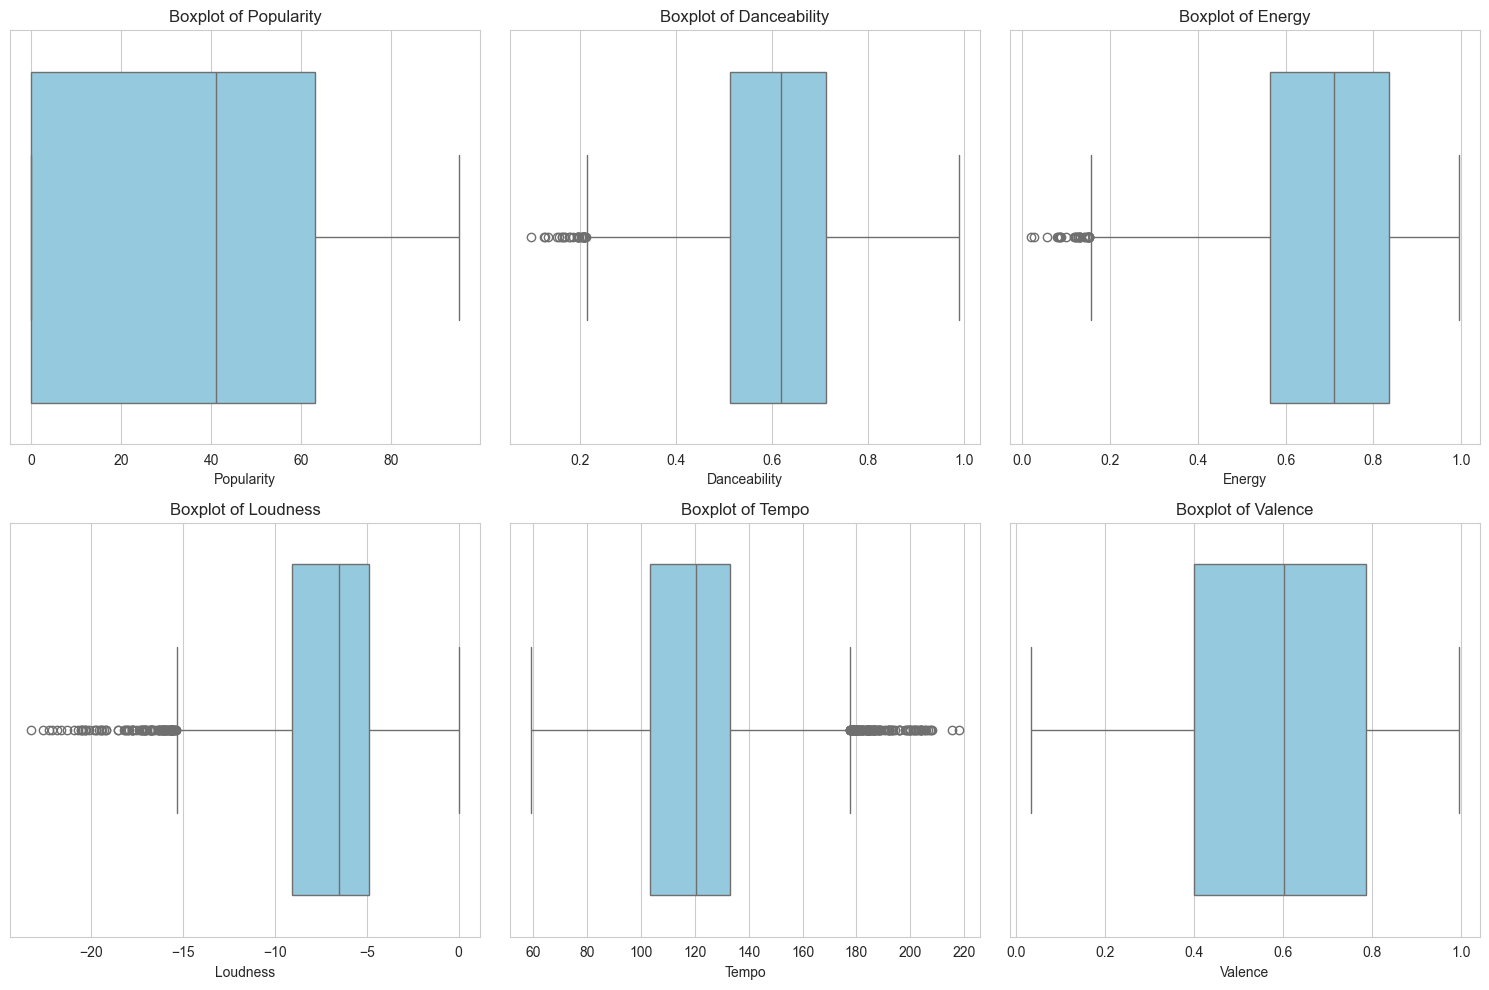

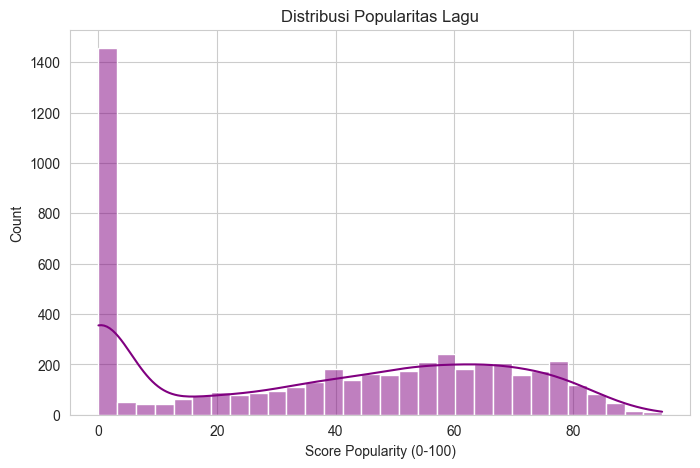

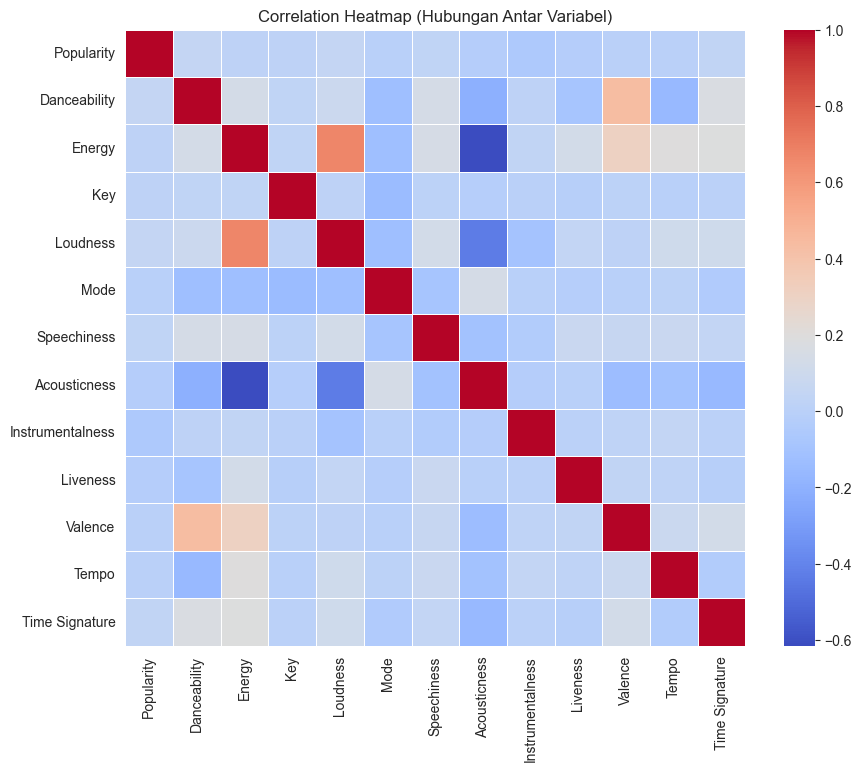

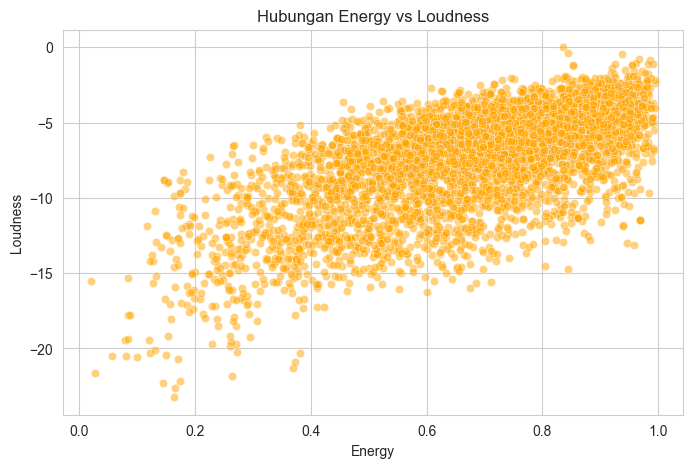

C:\Users\sudia\AppData\Local\Temp\ipykernel_10340\2671065242.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette='viridis')


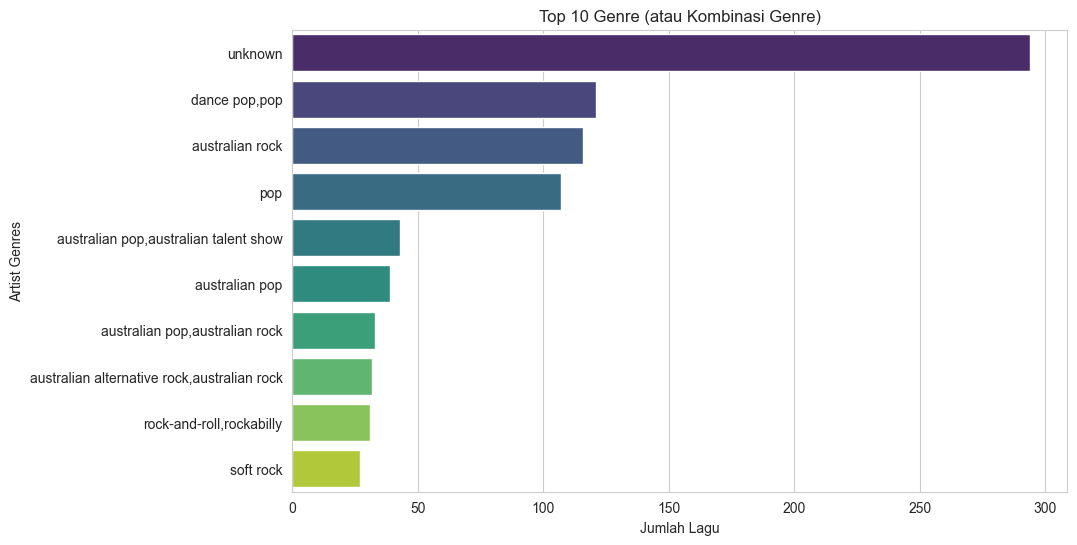

In [270]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

cols_to_plot = ['Popularity', 'Danceability', 'Energy', 'Loudness', 'Tempo', 'Valence']

plt.figure(figsize=(15, 10))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

#HISTOGRAM POPULARITY 
plt.figure(figsize=(8, 5))
sns.histplot(df['Popularity'], bins=30, kde=True, color='purple')
plt.title('Distribusi Popularitas Lagu')
plt.xlabel('Score Popularity (0-100)')
plt.show()

#CORRELATION HEATMAP 
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap (Hubungan Antar Variabel)')
plt.show()

#Hubungan Energy vs Loudness
# 
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Energy', y='Loudness', alpha=0.5, color='orange')
plt.title('Hubungan Energy vs Loudness')
plt.show()

#TOP 10 GENRES
plt.figure(figsize=(10, 6))
top_genres = df['Artist Genres'].value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index, palette='viridis')
plt.title('Top 10 Genre (atau Kombinasi Genre)')
plt.xlabel('Jumlah Lagu')
plt.show()

A. Conduct an Exploratory Data Analysis (EDA) on the dataset. Highlight the main insights and any irregularities you find, and address those anomalies appropriately! 

Based on an initial inspection of the dataset, several significant irregularities were identified that required addressing before further analysis. The main issues involved data quality, with nine duplicate rows, one row with a fatal missing Track Name, and hundreds of missing values ​​in the Artist, Genres, Tempo, and Acousticness columns. Furthermore, a physical anomaly was detected in the audio features, namely one song with a positive Loudness value (2,769 dB), which is invalid by digital audio standards. To address this, comprehensive remediation steps were implemented through the programming code, including removing duplicate and untitled rows, imputing missing values ​​using the median for numeric data and the "unknown" label for categories, and clipping Loudness values ​​to return the maximum threshold to 0 dB.

After data cleaning, statistical analysis and visualization using Correlation Heatmap and Scatter Plot revealed strong patterns of relationships between features. The most prominent finding was a high positive correlation (0.67) between Energy and Loudness, indicating that more energetic songs tend to have a higher volume. This linear relationship is confirmed through the Scatter Plot graph, which shows a consistent upward trend in the distribution of data points. Furthermore, there is a correlation between Valence and Danceability, indicating that songs with a positive or happy feel tend to be more danceable. Other audio characteristics are relatively standard, with the majority of songs having an average tempo of 120 BPM and a 4/4 time signature.

Analysis of the data distribution using Boxplots and Histograms highlights the characteristics of the popularity distribution and outliers. The popularity histogram shows a non-normal distribution, with approximately 27% of the data (1,344 songs) having a popularity score of 0. This indicates a large proportion of niche songs, older songs, or potential missing data from the source. Meanwhile, the Boxplot visualization helps identify statistical outliers in other audio features without having to remove them, as such variations are still considered normal in the musical context (e.g., very fast or slow tempos). Finally, the genre analysis reveals the dominance of certain categories, providing insight into musical trends within this dataset. This combination of data cleaning and visual analysis ensures better data integrity for future recommendation system development.

B. Create a content-based recommendation system, implemented as a function that takes a text input and returns five suggested items! 

In [271]:
feature_cols = ['Danceability', 'Energy', 'Key', 'Loudness', 'Mode', 
                'Speechiness', 'Acousticness', 'Instrumentalness', 
                'Liveness', 'Valence', 'Tempo']

scaler = MinMaxScaler()
audio_features = scaler.fit_transform(df[feature_cols])


df['text_features'] = df['Artist Genres'] + " " + df['Artist Name(s)']

tfidf = TfidfVectorizer(stop_words='english')
text_matrix = tfidf.fit_transform(df['text_features'].astype(str))

In [272]:
audio_sim = cosine_similarity(audio_features)
text_sim = cosine_similarity(text_matrix)


hybrid_sim = (audio_sim * 0.5) + (text_sim * 0.5)

indices = pd.Series(df.index, index=df['Track Name'].str.lower()).drop_duplicates()

In [273]:
def recommend_songs_fixed(query_text, df=df, top_n=5):
    query_lower = query_text.lower()
    scores = None
    mode = ""

    if query_lower in indices:
        mode = "Rekomendasi"
        idx = indices[query_lower]
        if isinstance(idx, pd.Series): idx = idx.iloc[0]
        
        scores = hybrid_sim[idx]

    else:
        mode = "Pencarian"
        query_vec = tfidf.transform([query_text])
        scores = cosine_similarity(query_vec, text_matrix).flatten()
        
        if scores.max() == 0:
            return pd.DataFrame([f"Maaf, tidak ditemukan hasil untuk '{query_text}'"], columns=["Pesan"])
    top_indices = scores.argsort()[-(top_n+10):][::-1]
    
    final_indices = []
    for i in top_indices:
        if df.iloc[i]['Track Name'].lower() == query_lower:
            continue
            
        final_indices.append(i)
        
        if len(final_indices) == top_n:
            break
    
    print(f"--- Mode: {mode} ---")
    return df.iloc[final_indices][['Track Name', 'Artist Name(s)', 'Artist Genres']]

In [274]:
#contoh
recommend_songs_fixed("If I Ain't Got You")

--- Mode: Rekomendasi ---


,Track Name,Artist Name(s),Artist Genres
2679,Empire State of Mind (Part II) Broken Down,Alicia Keys,"neo soul,pop,r&b"
2191,Girl On Fire,Alicia Keys,"neo soul,pop,r&b"
436,Tears Always Win,Alicia Keys,"neo soul,pop,r&b"
2234,Work On It,Alicia Keys,"neo soul,pop,r&b"
3380,Holy War,Alicia Keys,"neo soul,pop,r&b"


In [275]:
recommend_songs_fixed("romantic love acoustic")

--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
1276,Cocoon,Love Ghost,unknown
3473,Only Want You,"Love\, Marco",unknown
3180,Can I Go Now,Jennifer Love Hewitt,"dance pop,idol,post-teen pop"
4558,How Do I Deal,Jennifer Love Hewitt,"dance pop,idol,post-teen pop"
1415,Love's Theme,The Love Unlimited Orchestra,"classic soul,disco,post-disco"


In [276]:
recommend_songs_fixed("romantic love acoustic")


--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
1276,Cocoon,Love Ghost,unknown
3473,Only Want You,"Love\, Marco",unknown
3180,Can I Go Now,Jennifer Love Hewitt,"dance pop,idol,post-teen pop"
4558,How Do I Deal,Jennifer Love Hewitt,"dance pop,idol,post-teen pop"
1415,Love's Theme,The Love Unlimited Orchestra,"classic soul,disco,post-disco"


In [277]:
recommend_songs_fixed("sad piano slow")


--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
2111,death bed (coffee for your head),"Powfu, beabadoobee","sad lo-fi,sad rap,bedroom pop,bubblegrunge,ind..."
4161,Counting Stars,OneRepublic,"piano rock,pop"
4310,Apologize,OneRepublic,"piano rock,pop"
2961,Secrets,OneRepublic,"piano rock,pop"
3354,Something I Need,OneRepublic,"piano rock,pop"


In [278]:
recommend_songs_fixed("rock guitar energetic")


--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
4918,Give Me the Night,George Benson,"jazz funk,jazz guitar,smooth jazz,soul jazz,ya..."
1606,Give A Little Bit,Supertramp,"album rock,art rock,classic rock,glam rock,mel..."
2993,Hand Me Down World - Single Version,The Guess Who,"album rock,classic canadian rock,classic rock,..."
4180,American Woman,The Guess Who,"album rock,classic canadian rock,classic rock,..."
2641,Owner of a Lonely Heart,Yes,"album rock,art rock,classic rock,hard rock,pro..."


In [279]:
recommend_songs_fixed("shape of you")



--- Mode: Rekomendasi ---


,Track Name,Artist Name(s),Artist Genres
2429,Cold as Ice - 2008 Remaster,Foreigner,"album rock,classic rock,glam metal,hard rock,h..."
2410,Say You Will - 2008 Remaster,Foreigner,"album rock,classic rock,glam metal,hard rock,h..."
2422,Waiting for a Girl like You,Foreigner,"album rock,classic rock,glam metal,hard rock,h..."
4078,Hot Blooded,Foreigner,"album rock,classic rock,glam metal,hard rock,h..."
681,Juke Box Hero,Foreigner,"album rock,classic rock,glam metal,hard rock,h..."


In [280]:
recommend_songs_fixed("perfect")

--- Mode: Rekomendasi ---


,Track Name,Artist Name(s),Artist Genres
4128,Stockholm Syndrome,One Direction,"boy band,pop,post-teen pop,talent show"
4120,Story of My Life,One Direction,"boy band,pop,post-teen pop,talent show"
516,Love You Goodbye,One Direction,"boy band,pop,post-teen pop,talent show"
4788,One Thing,One Direction,"boy band,pop,post-teen pop,talent show"
3297,A.M.,One Direction,"boy band,pop,post-teen pop,talent show"


In [281]:
recommend_songs_fixed("If I Ain't Got You")

--- Mode: Rekomendasi ---


,Track Name,Artist Name(s),Artist Genres
2679,Empire State of Mind (Part II) Broken Down,Alicia Keys,"neo soul,pop,r&b"
2191,Girl On Fire,Alicia Keys,"neo soul,pop,r&b"
436,Tears Always Win,Alicia Keys,"neo soul,pop,r&b"
2234,Work On It,Alicia Keys,"neo soul,pop,r&b"
3380,Holy War,Alicia Keys,"neo soul,pop,r&b"


In [282]:
recommend_songs_fixed("Taylor Swift")

--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
2970,New Romantics,Taylor Swift,pop
4455,22,Taylor Swift,pop
3919,Out Of The Woods,Taylor Swift,pop
3106,I Forgot That You Existed,Taylor Swift,pop
4464,Delicate,Taylor Swift,pop


C. Provide a minimum of three inputs to the function and examine if the recommendations correspond to each input! 

In [283]:
recommend_songs_fixed("If I Ain't Got You")



--- Mode: Rekomendasi ---


,Track Name,Artist Name(s),Artist Genres
2679,Empire State of Mind (Part II) Broken Down,Alicia Keys,"neo soul,pop,r&b"
2191,Girl On Fire,Alicia Keys,"neo soul,pop,r&b"
436,Tears Always Win,Alicia Keys,"neo soul,pop,r&b"
2234,Work On It,Alicia Keys,"neo soul,pop,r&b"
3380,Holy War,Alicia Keys,"neo soul,pop,r&b"


In [284]:
recommend_songs_fixed("Taylor Swift")

--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
2970,New Romantics,Taylor Swift,pop
4455,22,Taylor Swift,pop
3919,Out Of The Woods,Taylor Swift,pop
3106,I Forgot That You Existed,Taylor Swift,pop
4464,Delicate,Taylor Swift,pop


In [285]:
recommend_songs_fixed("Disco")

--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
1415,Love's Theme,The Love Unlimited Orchestra,"classic soul,disco,post-disco"
2324,Don't Leave Me This Way,Thelma Houston,"disco,diva house,motown,post-disco"
4617,Nine in the Afternoon - Single Mix,Panic! At The Disco,pop
2048,The Ballad of Mona Lisa,Panic! At The Disco,pop
4170,High Hopes,Panic! At The Disco,pop


In [286]:
recommend_songs_fixed("romantic acoustic love")


--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
1276,Cocoon,Love Ghost,unknown
3473,Only Want You,"Love\, Marco",unknown
3180,Can I Go Now,Jennifer Love Hewitt,"dance pop,idol,post-teen pop"
4558,How Do I Deal,Jennifer Love Hewitt,"dance pop,idol,post-teen pop"
1415,Love's Theme,The Love Unlimited Orchestra,"classic soul,disco,post-disco"


In [287]:

recommend_songs_fixed("rock guitar energetic")

--- Mode: Pencarian ---


,Track Name,Artist Name(s),Artist Genres
4918,Give Me the Night,George Benson,"jazz funk,jazz guitar,smooth jazz,soul jazz,ya..."
1606,Give A Little Bit,Supertramp,"album rock,art rock,classic rock,glam rock,mel..."
2993,Hand Me Down World - Single Version,The Guess Who,"album rock,classic canadian rock,classic rock,..."
4180,American Woman,The Guess Who,"album rock,classic canadian rock,classic rock,..."
2641,Owner of a Lonely Heart,Yes,"album rock,art rock,classic rock,hard rock,pro..."


The recommendation system's performance was evaluated by testing five types of input to verify the flexibility of the Hybrid algorithm. 
For the first input, "If I Ain't Got You," the system activated content-based mode and accurately recommended songs by Alicia Keys with similar audio characteristics. 
The input "Taylor Swift" triggered a search mode that displayed the artist's discography. 
For the input "Disco," the system combed through genre metadata, resulting in a mix of classic disco songs and related artists. 
The system's ability to handle instrument descriptions was tested with the input "rock guitar energetic"; since the system couldn't find a song with that title,
 it searched the metadata for its keyword combination, resulting in relevant Classic Rock and Jazz Guitar songs, 
 demonstrating the system's ability to translate mood descriptions into music recommendations. 
 Finally, the input "romantic acoustic love" resulted in recommendations dominated by artists with names containing "Love," proving the dominant keyword search mechanism works effectively when specific phrases aren't found intact.